In [1]:
# Data manipulation and analysis
import pandas as pd
import numpy as np
import shap
import copy 
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_val_score
from sklearn.preprocessing import OneHotEncoder
from sklearn.compose import ColumnTransformer

# Machine Learning Models
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.svm import SVC
from xgboost import XGBClassifier
from catboost import CatBoostClassifier

# Hyperparameter Optimization with Optuna
import optuna
from optuna.samplers import TPESampler

# Evaluation Metrics
from sklearn.metrics import (
    roc_auc_score, 
    accuracy_score, 
    precision_score, 
    recall_score, 
    f1_score,
    classification_report,
    confusion_matrix
)

# Visualization
import matplotlib.pyplot as plt
import seaborn as sns

# Suppress warnings
import warnings
warnings.filterwarnings('ignore')
optuna.logging.set_verbosity(optuna.logging.WARNING)

# Set random seed for reproducibility
RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)

In [2]:
# Load the dataset
df = pd.read_csv('df.csv')

# Display basic information
print("Dataset Shape:", df.shape)
print("\n" + "="*50)
print("First few rows:")
print(df.head())
print("\n" + "="*50)
print("Dataset Info:")
print(df.info())
print("\n" + "="*50)
print("Missing Values:")
print(df.isnull().sum())
print("\n" + "="*50)
print("Target Variable Distribution:")
print(df['HIVDR_presence'].value_counts())
print("\nTarget Variable Proportions:")
print(df['HIVDR_presence'].value_counts(normalize=True))

Dataset Shape: (1191, 5)

First few rows:
  HIVDR_presence           cd4cat          artduration          arvstatus  \
0             No        CD4 ≥ 500   On ART < 12 months      ARVs detected   
1             No        CD4 < 200   On ART ≥ 24 months  ARVs not detected   
2            Yes  350 ≤ CD4 < 500   On ART ≥ 24 months  ARVs not detected   
3             No        CD4 ≥ 500  On ART 12-23 months  ARVs not detected   
4            Yes  350 ≤ CD4 < 500   On ART ≥ 24 months      ARVs detected   

                       awareartselfreported  
0  Self-report previously diagnosed, on ART  
1  Self-report previously diagnosed, on ART  
2  Self-report previously diagnosed, on ART  
3  Self-report previously diagnosed, on ART  
4  Self-report previously diagnosed, on ART  

Dataset Info:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1191 entries, 0 to 1190
Data columns (total 5 columns):
 #   Column                Non-Null Count  Dtype 
---  ------                --------------  -----

In [3]:
# Define feature columns and target
feature_columns = ['cd4cat', 'artduration', 'arvstatus', 'awareartselfreported']
target_column = 'HIVDR_presence'

# Separate features and target
X = df[feature_columns].copy()
y = df[target_column].copy()

print("Features shape:", X.shape)
print("Target shape:", y.shape)
print("\n" + "="*50)
print("Feature data types:")
print(X.dtypes)

Features shape: (1191, 4)
Target shape: (1191,)

Feature data types:
cd4cat                  object
artduration             object
arvstatus               object
awareartselfreported    object
dtype: object


In [4]:
# Check current data type of target variable
print("Current target variable values:")
print(y.value_counts())
print("\nTarget variable data type:", y.dtype)

# Encode target variable to numeric (0, 1)
from sklearn.preprocessing import LabelEncoder

# Create label encoder
label_encoder = LabelEncoder()

# Fit and transform the target variable
y_encoded = label_encoder.fit_transform(y)

# Convert back to pandas Series for easier handling
y = pd.Series(y_encoded, index=y.index, name=target_column)

# Display the mapping
print("\n" + "="*50)
print("Target Variable Encoding:")
print("="*50)
for i, class_label in enumerate(label_encoder.classes_):
    print(f"{class_label} --> {i}")

print("\nEncoded target variable values:")
print(y.value_counts())
print("\nTarget variable data type:", y.dtype)

Current target variable values:
HIVDR_presence
No     620
Yes    571
Name: count, dtype: int64

Target variable data type: object

Target Variable Encoding:
No --> 0
Yes --> 1

Encoded target variable values:
HIVDR_presence
0    620
1    571
Name: count, dtype: int64

Target variable data type: int64


In [5]:
# Perform stratified train-test split
X_train, X_test, y_train, y_test = train_test_split(
    X, y, 
    test_size=0.20, 
    random_state=RANDOM_STATE, 
    stratify=y
)

print("Training set size:", X_train.shape[0], f"({X_train.shape[0]/len(X)*100:.1f}%)")
print("Test set size:", X_test.shape[0], f"({X_test.shape[0]/len(X)*100:.1f}%)")
print("\n" + "="*50)
print("Training set target distribution:")
print(y_train.value_counts())
print("\nTest set target distribution:")
print(y_test.value_counts())

Training set size: 952 (79.9%)
Test set size: 239 (20.1%)

Training set target distribution:
HIVDR_presence
0    496
1    456
Name: count, dtype: int64

Test set target distribution:
HIVDR_presence
0    124
1    115
Name: count, dtype: int64


In [6]:
# Store original categorical data for CatBoost
X_train_cat = X_train.copy()
X_test_cat = X_test.copy()

# Identify categorical columns
categorical_features = X_train.columns.tolist()

# Create one-hot encoder
encoder = OneHotEncoder(drop='first', sparse_output=False, handle_unknown='ignore')

# Fit encoder on training data and transform both sets
X_train_encoded = encoder.fit_transform(X_train)
X_test_encoded = encoder.transform(X_test)

# Get feature names after encoding
encoded_feature_names = encoder.get_feature_names_out(categorical_features)

# Convert to DataFrames for better handling
X_train_encoded_df = pd.DataFrame(X_train_encoded, columns=encoded_feature_names)
X_test_encoded_df = pd.DataFrame(X_test_encoded, columns=encoded_feature_names)

print("Original number of features:", len(categorical_features))
print("Number of features after one-hot encoding:", X_train_encoded.shape[1])
print("\n" + "="*50)
print("Encoded feature names:")
print(list(encoded_feature_names))

Original number of features: 4
Number of features after one-hot encoding: 9

Encoded feature names:
['cd4cat_350 ≤ CD4 < 500', 'cd4cat_CD4 < 200', 'cd4cat_CD4 ≥ 500', 'artduration_On ART 12-23 months', 'artduration_On ART < 12 months', 'artduration_On ART ≥ 24 months', 'arvstatus_ARVs not detected', 'awareartselfreported_Self-report previously diagnosed, not on ART', 'awareartselfreported_Self-report previously diagnosed, on ART']


In [7]:
X_train_encoded_df

,cd4cat_350 ≤ CD4 < 500,cd4cat_CD4 < 200,cd4cat_CD4 ≥ 500,artduration_On ART 12-23 months,artduration_On ART < 12 months,artduration_On ART ≥ 24 months,arvstatus_ARVs not detected,"awareartselfreported_Self-report previously diagnosed, not on ART","awareartselfreported_Self-report previously diagnosed, on ART"
0,0.0,1.0,0.0,0.0,1.0,0.0,0.0,0.0,1.0
1,0.0,0.0,1.0,0.0,0.0,0.0,1.0,0.0,0.0
2,0.0,0.0,1.0,0.0,0.0,0.0,1.0,0.0,0.0
3,0.0,0.0,1.0,0.0,0.0,0.0,1.0,1.0,0.0
4,0.0,1.0,0.0,0.0,0.0,1.0,0.0,0.0,1.0
...,...,...,...,...,...,...,...,...,...
947,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,1.0
948,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
949,0.0,0.0,1.0,0.0,0.0,0.0,1.0,0.0,0.0
950,0.0,0.0,1.0,0.0,0.0,0.0,1.0,0.0,0.0


In [8]:
# Define the cross-validation strategy
cv_strategy = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)

# 1. LOGISTIC REGRESSION OBJECTIVE FUNCTION
def objective_lr(trial):
    """Objective function for Logistic Regression hyperparameter optimization"""
    
    # Suggest hyperparameters
    params = {
        'C': trial.suggest_float('C', 0.001, 100, log=True),
        'penalty': trial.suggest_categorical('penalty', ['l1', 'l2']),
        'solver': trial.suggest_categorical('solver', ['liblinear', 'saga']),
        'max_iter': 1000,
        'random_state': RANDOM_STATE
    }
    
    # Create model with suggested parameters
    model = LogisticRegression(**params)
    
    # Perform cross-validation
    scores = cross_val_score(
        model, 
        X_train_encoded, 
        y_train, 
        cv=cv_strategy, 
        scoring='roc_auc',
        n_jobs=-1
    )
    
    # Return mean ROC-AUC score
    return scores.mean()


# 2. RANDOM FOREST OBJECTIVE FUNCTION
def objective_rf(trial):
    """Objective function for Random Forest hyperparameter optimization"""
    
    # Suggest hyperparameters
    params = {
        'n_estimators': trial.suggest_int('n_estimators', 50, 500),
        'max_depth': trial.suggest_int('max_depth', 3, 20),
        'min_samples_split': trial.suggest_int('min_samples_split', 2, 20),
        'min_samples_leaf': trial.suggest_int('min_samples_leaf', 1, 10),
        'max_features': trial.suggest_categorical('max_features', ['sqrt', 'log2']),
        'class_weight': trial.suggest_categorical('class_weight', ['balanced', None]),
        'random_state': RANDOM_STATE
    }
    
    # Create model with suggested parameters
    model = RandomForestClassifier(**params)
    
    # Perform cross-validation
    scores = cross_val_score(
        model, 
        X_train_encoded, 
        y_train, 
        cv=cv_strategy, 
        scoring='roc_auc',
        n_jobs=-1
    )
    
    # Return mean ROC-AUC score
    return scores.mean()


# 3. SVM OBJECTIVE FUNCTION
def objective_svm(trial):
    """Objective function for SVM hyperparameter optimization"""
    
    # Suggest hyperparameters
    params = {
        'C': trial.suggest_float('C', 0.01, 100, log=True),
        'kernel': trial.suggest_categorical('kernel', ['rbf', 'linear']),
        'gamma': trial.suggest_categorical('gamma', ['scale', 'auto']),
        'class_weight': trial.suggest_categorical('class_weight', ['balanced', None]),
        'probability': True,
        'random_state': RANDOM_STATE
    }
    
    # Create model with suggested parameters
    model = SVC(**params)
    
    # Perform cross-validation
    scores = cross_val_score(
        model, 
        X_train_encoded, 
        y_train, 
        cv=cv_strategy, 
        scoring='roc_auc',
        n_jobs=-1
    )
    
    # Return mean ROC-AUC score
    return scores.mean()


# 4. XGBOOST OBJECTIVE FUNCTION
def objective_xgb(trial):
    """Objective function for XGBoost hyperparameter optimization"""
    
    # Suggest hyperparameters
    params = {
        'n_estimators': trial.suggest_int('n_estimators', 50, 500),
        'max_depth': trial.suggest_int('max_depth', 3, 15),
        'learning_rate': trial.suggest_float('learning_rate', 0.01, 0.3, log=True),
        'subsample': trial.suggest_float('subsample', 0.6, 1.0),
        'colsample_bytree': trial.suggest_float('colsample_bytree', 0.6, 1.0),
        'gamma': trial.suggest_float('gamma', 0, 5),
        'min_child_weight': trial.suggest_int('min_child_weight', 1, 10),
        'scale_pos_weight': trial.suggest_float('scale_pos_weight', 0.5, 2.0),
        'random_state': RANDOM_STATE,
        'eval_metric': 'logloss'
    }
    
    # Create model with suggested parameters
    model = XGBClassifier(**params)
    
    # Perform cross-validation
    scores = cross_val_score(
        model, 
        X_train_encoded, 
        y_train, 
        cv=cv_strategy, 
        scoring='roc_auc',
        n_jobs=-1
    )
    
    # Return mean ROC-AUC score
    return scores.mean()


# 5. CATBOOST OBJECTIVE FUNCTION
def objective_catboost(trial):
    """Objective function for CatBoost hyperparameter optimization"""
    
    # Suggest hyperparameters
    params = {
        'iterations': trial.suggest_int('iterations', 50, 500),
        'depth': trial.suggest_int('depth', 3, 10),
        'learning_rate': trial.suggest_float('learning_rate', 0.01, 0.3, log=True),
        'l2_leaf_reg': trial.suggest_float('l2_leaf_reg', 1, 10),
        'border_count': trial.suggest_int('border_count', 32, 255),
        'scale_pos_weight': trial.suggest_float('scale_pos_weight', 0.5, 2.0),
        'cat_features': list(range(len(categorical_features))),
        'random_state': RANDOM_STATE,
        'verbose': 0
    }
    
    # Create model with suggested parameters
    model = CatBoostClassifier(**params)
    
    # Perform cross-validation on original categorical data
    scores = cross_val_score(
        model, 
        X_train_cat, 
        y_train, 
        cv=cv_strategy, 
        scoring='roc_auc',
        n_jobs=-1
    )
    
    # Return mean ROC-AUC score
    return scores.mean()

print("Objective functions defined for all 5 models")

Objective functions defined for all 5 models


In [9]:
print("="*70)
print("LOGISTIC REGRESSION - Hyperparameter Optimization with Optuna")
print("="*70)

# Create Optuna study
study_lr = optuna.create_study(
    direction='maximize',
    sampler=TPESampler(seed=RANDOM_STATE),
    study_name='Logistic_Regression_Optimization'
)

# Optimize
study_lr.optimize(objective_lr, n_trials=100, show_progress_bar=True)

# Get best parameters and score
print("\nOptimization Complete!")
print("Best Parameters:", study_lr.best_params)
print("Best Cross-Validation ROC-AUC:", study_lr.best_value)

# Train final model with best parameters
lr_best_params = study_lr.best_params
lr_best_params['random_state'] = RANDOM_STATE
lr_best_params['max_iter'] = 1000

lr_best = LogisticRegression(**lr_best_params)
lr_best.fit(X_train_encoded, y_train)

print(f"\nNumber of trials completed: {len(study_lr.trials)}")

LOGISTIC REGRESSION - Hyperparameter Optimization with Optuna


  0%|          | 0/100 [00:00<?, ?it/s]


Optimization Complete!
Best Parameters: {'C': 0.10054682153549799, 'penalty': 'l2', 'solver': 'liblinear'}
Best Cross-Validation ROC-AUC: 0.8400704271573837

Number of trials completed: 100


In [10]:
print("\n" + "="*70)
print("RANDOM FOREST - Hyperparameter Optimization with Optuna")
print("="*70)

# Create Optuna study
study_rf = optuna.create_study(
    direction='maximize',
    sampler=TPESampler(seed=RANDOM_STATE),
    study_name='Random_Forest_Optimization'
)

# Optimize
study_rf.optimize(objective_rf, n_trials=100, show_progress_bar=True)

# Get best parameters and score
print("\nOptimization Complete!")
print("Best Parameters:", study_rf.best_params)
print("Best Cross-Validation ROC-AUC:", study_rf.best_value)

# Train final model with best parameters
rf_best_params = study_rf.best_params
rf_best_params['random_state'] = RANDOM_STATE

rf_best = RandomForestClassifier(**rf_best_params)
rf_best.fit(X_train_encoded, y_train)

print(f"\nNumber of trials completed: {len(study_rf.trials)}")


RANDOM FOREST - Hyperparameter Optimization with Optuna


  0%|          | 0/100 [00:00<?, ?it/s]


Optimization Complete!
Best Parameters: {'n_estimators': 439, 'max_depth': 5, 'min_samples_split': 7, 'min_samples_leaf': 1, 'max_features': 'log2', 'class_weight': 'balanced'}
Best Cross-Validation ROC-AUC: 0.8494488747967008

Number of trials completed: 100


In [11]:
print("\n" + "="*70)
print("SUPPORT VECTOR MACHINE - Hyperparameter Optimization with Optuna")
print("="*70)

# Create Optuna study
study_svm = optuna.create_study(
    direction='maximize',
    sampler=TPESampler(seed=RANDOM_STATE),
    study_name='SVM_Optimization'
)

# Optimize
study_svm.optimize(objective_svm, n_trials=100, show_progress_bar=True)

# Get best parameters and score
print("\nOptimization Complete!")
print("Best Parameters:", study_svm.best_params)
print("Best Cross-Validation ROC-AUC:", study_svm.best_value)

# Train final model with best parameters
svm_best_params = study_svm.best_params
svm_best_params['random_state'] = RANDOM_STATE
svm_best_params['probability'] = True

svm_best = SVC(**svm_best_params)
svm_best.fit(X_train_encoded, y_train)

print(f"\nNumber of trials completed: {len(study_svm.trials)}")


SUPPORT VECTOR MACHINE - Hyperparameter Optimization with Optuna


  0%|          | 0/100 [00:00<?, ?it/s]


Optimization Complete!
Best Parameters: {'C': 0.02640638971281672, 'kernel': 'rbf', 'gamma': 'scale', 'class_weight': None}
Best Cross-Validation ROC-AUC: 0.8490678548504634

Number of trials completed: 100


In [12]:
import warnings
# Suppress XGBoost warnings about deprecated parameters
warnings.filterwarnings('ignore', category=UserWarning, module='xgboost')

# Then continue with your existing Step 10 code...

print("\n" + "="*70)
print("XGBOOST - Hyperparameter Optimization with Optuna")
print("="*70)

# Create Optuna study
study_xgb = optuna.create_study(
    direction='maximize',
    sampler=TPESampler(seed=RANDOM_STATE),
    study_name='XGBoost_Optimization'
)

# Optimize
study_xgb.optimize(objective_xgb, n_trials=100, show_progress_bar=True)

# Get best parameters and score
print("\nOptimization Complete!")
print("Best Parameters:", study_xgb.best_params)
print("Best Cross-Validation ROC-AUC:", study_xgb.best_value)

# Train final model with best parameters
xgb_best_params = study_xgb.best_params
xgb_best_params['random_state'] = RANDOM_STATE
xgb_best_params['eval_metric'] = 'logloss'


xgb_best = XGBClassifier(**xgb_best_params)
xgb_best.fit(X_train_encoded, y_train)

print(f"\nNumber of trials completed: {len(study_xgb.trials)}")


XGBOOST - Hyperparameter Optimization with Optuna


  0%|          | 0/100 [00:00<?, ?it/s]


Optimization Complete!
Best Parameters: {'n_estimators': 499, 'max_depth': 10, 'learning_rate': 0.2638561976256003, 'subsample': 0.7467415578397094, 'colsample_bytree': 0.7392419138898999, 'gamma': 1.8548697818451996, 'min_child_weight': 2, 'scale_pos_weight': 1.772628777787199}
Best Cross-Validation ROC-AUC: 0.8536054332141289

Number of trials completed: 100


In [13]:
print("\n" + "="*70)
print("CATBOOST - Hyperparameter Optimization with Optuna")
print("="*70)

# Create Optuna study
study_catboost = optuna.create_study(
    direction='maximize',
    sampler=TPESampler(seed=RANDOM_STATE),
    study_name='CatBoost_Optimization'
)

# Optimize
study_catboost.optimize(objective_catboost, n_trials=100, show_progress_bar=True)

# Get best parameters and score
print("\nOptimization Complete!")
print("Best Parameters:", study_catboost.best_params)
print("Best Cross-Validation ROC-AUC:", study_catboost.best_value)

# Train final model with best parameters
catboost_best_params = study_catboost.best_params
catboost_best_params['random_state'] = RANDOM_STATE
catboost_best_params['cat_features'] = list(range(len(categorical_features)))
catboost_best_params['verbose'] = 0

catboost_best = CatBoostClassifier(**catboost_best_params)
catboost_best.fit(X_train_cat, y_train)

print(f"\nNumber of trials completed: {len(study_catboost.trials)}")


CATBOOST - Hyperparameter Optimization with Optuna


  0%|          | 0/100 [00:00<?, ?it/s]


Optimization Complete!
Best Parameters: {'iterations': 437, 'depth': 5, 'learning_rate': 0.027749923953756795, 'l2_leaf_reg': 4.03283759949603, 'border_count': 205, 'scale_pos_weight': 0.9676131018741171}
Best Cross-Validation ROC-AUC: 0.8519307311046441

Number of trials completed: 100


In [14]:
print("\n" + "="*70)
print("GENERATING PREDICTIONS ON TEST SET")
print("="*70)

# Make predictions with each model
# For LR, RF, SVM, XGBoost: use one-hot encoded data
y_pred_lr = lr_best.predict(X_test_encoded)
y_pred_proba_lr = lr_best.predict_proba(X_test_encoded)[:, 1]

y_pred_rf = rf_best.predict(X_test_encoded)
y_pred_proba_rf = rf_best.predict_proba(X_test_encoded)[:, 1]

y_pred_svm = svm_best.predict(X_test_encoded)
y_pred_proba_svm = svm_best.predict_proba(X_test_encoded)[:, 1]

y_pred_xgb = xgb_best.predict(X_test_encoded)
y_pred_proba_xgb = xgb_best.predict_proba(X_test_encoded)[:, 1]

# For CatBoost: use original categorical data
y_pred_catboost = catboost_best.predict(X_test_cat)
y_pred_proba_catboost = catboost_best.predict_proba(X_test_cat)[:, 1]

print("Predictions generated for all models")


GENERATING PREDICTIONS ON TEST SET
Predictions generated for all models


In [15]:
print("\n" + "="*70)
print("CALCULATING EVALUATION METRICS")
print("="*70)

# Function to calculate all metrics
def calculate_metrics(y_true, y_pred, y_pred_proba, model_name):
    metrics = {
        'Model': model_name,
        'ROC-AUC': roc_auc_score(y_true, y_pred_proba),
        'Accuracy': accuracy_score(y_true, y_pred),
        'Precision': precision_score(y_true, y_pred, zero_division=0),
        'Recall': recall_score(y_true, y_pred, zero_division=0),
        'F1-Score': f1_score(y_true, y_pred, zero_division=0)
    }
    return metrics

# Calculate metrics for all models
metrics_lr = calculate_metrics(y_test, y_pred_lr, y_pred_proba_lr, 'Logistic Regression')
metrics_rf = calculate_metrics(y_test, y_pred_rf, y_pred_proba_rf, 'Random Forest')
metrics_svm = calculate_metrics(y_test, y_pred_svm, y_pred_proba_svm, 'SVM')
metrics_xgb = calculate_metrics(y_test, y_pred_xgb, y_pred_proba_xgb, 'XGBoost')
metrics_catboost = calculate_metrics(y_test, y_pred_catboost, y_pred_proba_catboost, 'CatBoost')

# Combine all metrics into a DataFrame
results_df = pd.DataFrame([
    metrics_lr,
    metrics_rf,
    metrics_svm,
    metrics_xgb,
    metrics_catboost
])

# Sort by ROC-AUC (descending)
results_df = results_df.sort_values('ROC-AUC', ascending=False).reset_index(drop=True)

print("\n" + "="*70)
print("MODEL PERFORMANCE COMPARISON")
print("="*70)
print(results_df.to_string(index=False))

# Identify the best model
best_model_name = results_df.iloc[0]['Model']
best_roc_auc = results_df.iloc[0]['ROC-AUC']

print("\n" + "="*70)
print(f"BEST MODEL: {best_model_name}")
print(f"Best Test Set ROC-AUC: {best_roc_auc:.4f}")
print("="*70)


CALCULATING EVALUATION METRICS

MODEL PERFORMANCE COMPARISON
              Model  ROC-AUC  Accuracy  Precision   Recall  F1-Score
           CatBoost 0.830119  0.774059   0.801980 0.704348  0.750000
      Random Forest 0.830119  0.774059   0.796117 0.713043  0.752294
            XGBoost 0.827525  0.765690   0.756522 0.756522  0.756522
                SVM 0.825421  0.778243   0.787037 0.739130  0.762332
Logistic Regression 0.815463  0.769874   0.794118 0.704348  0.746544

BEST MODEL: CatBoost
Best Test Set ROC-AUC: 0.8301



GENERATING ROC CURVE VISUALIZATIONS

ROC curve saved as 'roc_curve_comparison.png'


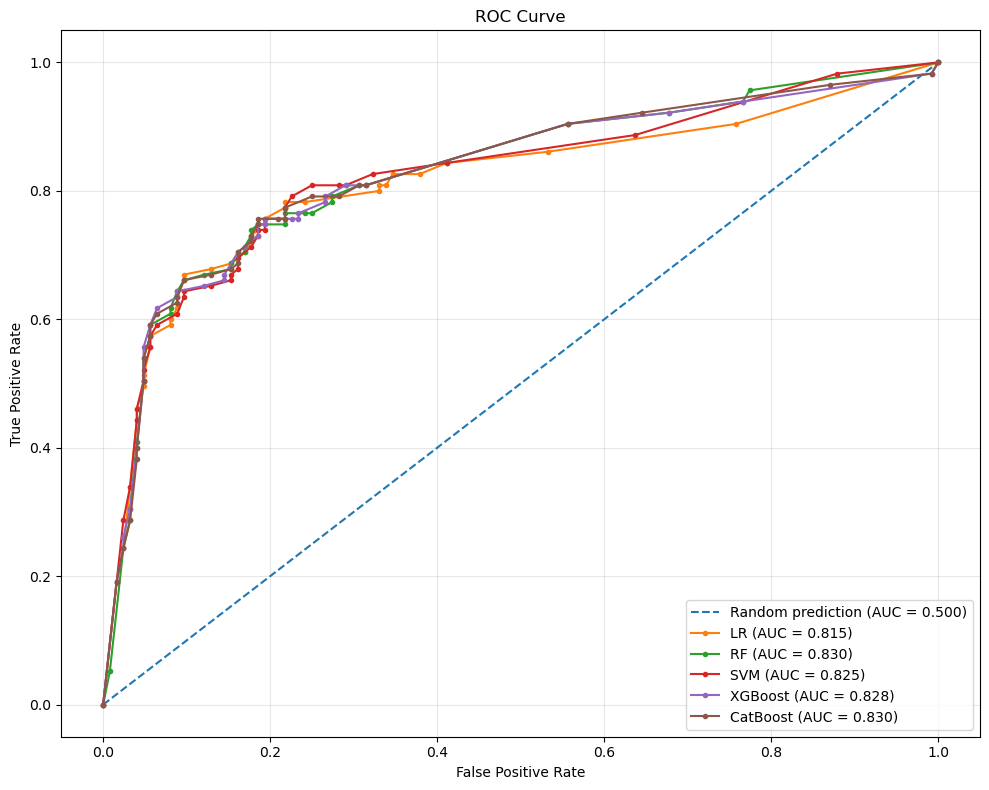


AUROC SCORES
Random Prediction: AUC = 0.500
Logistic Regression: AUC = 0.815
Random Forest: AUC = 0.830
SVM: AUROC = 0.825
XGBoost: AUC = 0.828
CatBoost: AUC = 0.830


In [16]:
from sklearn.metrics import roc_curve, auc

print("\n" + "="*70)
print("GENERATING ROC CURVE VISUALIZATIONS")
print("="*70)

# Calculate ROC curves for all models
fpr_lr, tpr_lr, _ = roc_curve(y_test, y_pred_proba_lr)
fpr_rf, tpr_rf, _ = roc_curve(y_test, y_pred_proba_rf)
fpr_svm, tpr_svm, _ = roc_curve(y_test, y_pred_proba_svm)
fpr_xgb, tpr_xgb, _ = roc_curve(y_test, y_pred_proba_xgb)
fpr_catboost, tpr_catboost, _ = roc_curve(y_test, y_pred_proba_catboost)

# Calculate AUC scores
roc_auc_lr = auc(fpr_lr, tpr_lr)
roc_auc_rf = auc(fpr_rf, tpr_rf)
roc_auc_svm = auc(fpr_svm, tpr_svm)
roc_auc_xgb = auc(fpr_xgb, tpr_xgb)
roc_auc_catboost = auc(fpr_catboost, tpr_catboost)

# Create the ROC plot
plt.figure(figsize=(10, 8))

# Plot random prediction (diagonal line)
plt.plot([0, 1], [0, 1], linestyle='--', label='Random prediction (AUC = 0.500)')

# Plot each model's ROC curve
plt.plot(fpr_lr, tpr_lr, marker='.', label='LR (AUC = %.3f)' % roc_auc_lr)
plt.plot(fpr_rf, tpr_rf, marker='.', label='RF (AUC = %.3f)' % roc_auc_rf)
plt.plot(fpr_svm, tpr_svm, marker='.', label='SVM (AUC = %.3f)' % roc_auc_svm)
plt.plot(fpr_xgb, tpr_xgb, marker='.', label='XGBoost (AUC = %.3f)' % roc_auc_xgb)
plt.plot(fpr_catboost, tpr_catboost, marker='.', label='CatBoost (AUC = %.3f)' % roc_auc_catboost)

# Title and labels
plt.title('ROC Curve')
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')

# Show legend
plt.legend(loc='lower right')

# Display plot
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.savefig('roc_curve_comparison.png', dpi=300, bbox_inches='tight')
print("\nROC curve saved as 'roc_curve_comparison.png'")
plt.show()

# Print AUROC scores
print("\n" + "="*70)
print("AUROC SCORES")
print("="*70)
print('Random Prediction: AUC = %.3f' % 0.500)
print('Logistic Regression: AUC = %.3f' % roc_auc_lr)
print('Random Forest: AUC = %.3f' % roc_auc_rf)
print('SVM: AUROC = %.3f' % roc_auc_svm)
print('XGBoost: AUC = %.3f' % roc_auc_xgb)
print('CatBoost: AUC = %.3f' % roc_auc_catboost)
print("="*70)

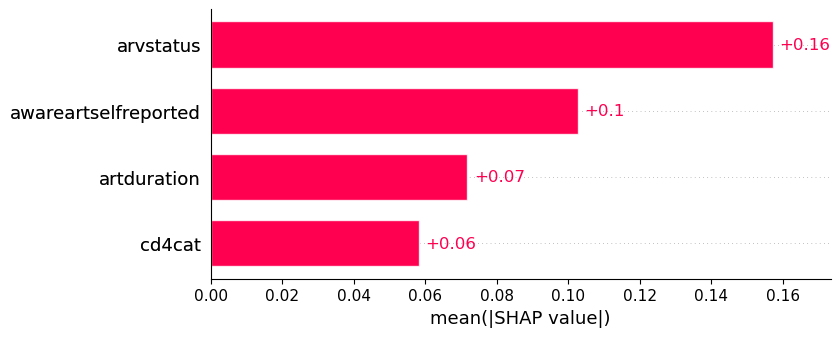

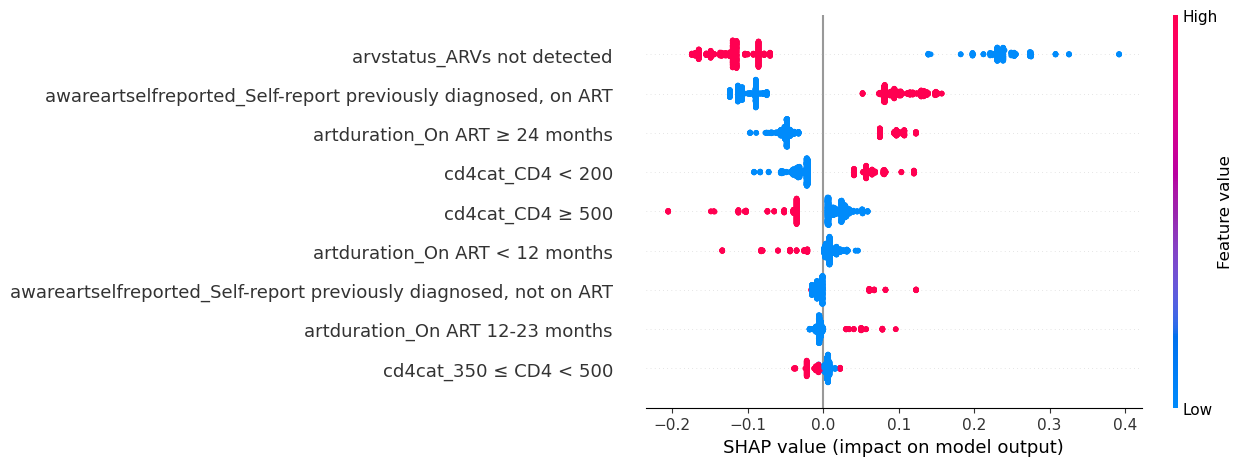

In [17]:
explainer = shap.Explainer(rf_best)
shap_values = explainer(X_train_encoded_df)
shap_values_copy = copy.deepcopy(shap_values)



def combine_one_hot(shap_values, name, mask, return_original=True):
    """  shap_values: an Explanation object
          name: name of new feature
          mask: bool array same lenght as features

         This function assumes that shap_values[:, mask] make up a one-hot-encoded feature
    """
    mask = np.array(mask)
    mask_col_names = np.array(shap_values.feature_names, dtype='object')[mask]

    sv_name = shap.Explanation(shap_values.values[:, mask],
                               feature_names=list(mask_col_names),
                               data=shap_values.data[:, mask],
                               base_values=shap_values.base_values,
                               display_data=shap_values.display_data,
                               instance_names=shap_values.instance_names,
                               output_names=shap_values.output_names,
                               output_indexes=shap_values.output_indexes,
                               lower_bounds=shap_values.lower_bounds,
                               upper_bounds=shap_values.upper_bounds,
                               main_effects=shap_values.main_effects,
                               hierarchical_values=shap_values.hierarchical_values,
                               clustering=shap_values.clustering,
                               )

    new_data = (sv_name.data * np.arange(sum(mask))).sum(axis=1).astype(int)

    svdata = np.concatenate([
        shap_values.data[:, ~mask],
        new_data.reshape(-1, 1)
    ], axis=1)

    if shap_values.display_data is None:
        svdd = shap_values.data[:, ~mask]
    else:
        svdd = shap_values.display_data[:, ~mask]

    svdisplay_data = np.concatenate([
        svdd,
        mask_col_names[new_data].reshape(-1, 1)
    ], axis=1)

    new_values = sv_name.values.sum(axis=1)
    svvalues = np.concatenate([
        shap_values.values[:, ~mask],
        new_values.reshape(-1, 1)
    ], axis=1)
    svfeature_names = list(np.array(shap_values.feature_names)[~mask]) + [name]

    sv = shap.Explanation(svvalues,
                          base_values=shap_values.base_values,
                          data=svdata,
                          display_data=svdisplay_data,
                          instance_names=shap_values.instance_names,
                          feature_names=svfeature_names,
                          output_names=shap_values.output_names,
                          output_indexes=shap_values.output_indexes,
                          lower_bounds=shap_values.lower_bounds,
                          upper_bounds=shap_values.upper_bounds,
                          main_effects=shap_values.main_effects,
                          hierarchical_values=shap_values.hierarchical_values,
                          clustering=shap_values.clustering,
                          )
    if return_original:
        return sv, sv_name
    else:
        return sv

shap_values,sv_occ = combine_one_hot(shap_values[:, :, 1], "cd4cat", ["cd4cat" in n for n in shap_values.feature_names])
shap_values,sv_occ = combine_one_hot(shap_values, "artduration", ["artduration" in n for n in shap_values.feature_names])
shap_values,sv_occ = combine_one_hot(shap_values, "arvstatus", ["arvstatus" in n for n in shap_values.feature_names])
shap_values,sv_occ = combine_one_hot(shap_values, "awareartselfreported", ["awareartselfreported" in n for n in shap_values.feature_names])

shap.plots.bar(shap_values)
shap.plots.beeswarm(shap_values_copy[:, :, 1])